In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier

from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score
)

Cell 2 – Load the dataset

In [2]:
df = pd.read_csv("diabetes.csv")

print("First 5 records:")
print(df.head())

print("\nLast 5 records:")
print(df.tail())

print("\nDataset Shape:")
print(df.shape)

print("\nDataset Information:")
print(df.info())

print("\nStatistical Summary:")
print(df.describe())

print("\nMissing Values:")
print(df.isnull().sum())

First 5 records:
   Pregnancies  Glucose  BloodPressure  SkinThickness  Insulin   BMI  \
0            6      148             72             35        0  33.6   
1            1       85             66             29        0  26.6   
2            8      183             64              0        0  23.3   
3            1       89             66             23       94  28.1   
4            0      137             40             35      168  43.1   

   Pedigree  Age  Outcome  
0     0.627   50        1  
1     0.351   31        0  
2     0.672   32        1  
3     0.167   21        0  
4     2.288   33        1  

Last 5 records:
     Pregnancies  Glucose  BloodPressure  SkinThickness  Insulin   BMI  \
763           10      101             76             48      180  32.9   
764            2      122             70             27        0  36.8   
765            5      121             72             23      112  26.2   
766            1      126             60              0        0  30.

Cell 3 – Data preprocessing

In [3]:
# Replace invalid zeros with median values
columns = [
    "Glucose",
    "BloodPressure",
    "SkinThickness",
    "Insulin",
    "BMI"
]

for col in columns:
    df[col] = df[col].replace(0, np.nan)
    df[col] = df[col].fillna(df[col].median())

print("Missing values after preprocessing:")
print(df.isnull().sum())

print("\nPreprocessed Dataset:")
print(df.head())

Missing values after preprocessing:
Pregnancies      0
Glucose          0
BloodPressure    0
SkinThickness    0
Insulin          0
BMI              0
Pedigree         0
Age              0
Outcome          0
dtype: int64

Preprocessed Dataset:
   Pregnancies  Glucose  BloodPressure  SkinThickness  Insulin   BMI  \
0            6    148.0           72.0           35.0    125.0  33.6   
1            1     85.0           66.0           29.0    125.0  26.6   
2            8    183.0           64.0           29.0    125.0  23.3   
3            1     89.0           66.0           23.0     94.0  28.1   
4            0    137.0           40.0           35.0    168.0  43.1   

   Pedigree  Age  Outcome  
0     0.627   50        1  
1     0.351   31        0  
2     0.672   32        1  
3     0.167   21        0  
4     2.288   33        1  


Cell 4 – Separate features and target variable

In [4]:
# Independent variables
X = df.drop("Outcome", axis=1)

# Dependent variable
y = df["Outcome"]

print("Independent Variables:")
print(X.head())

print("\nTarget Variable:")
print(y.head())

print("\nClass Distribution:")
print(y.value_counts())

Independent Variables:
   Pregnancies  Glucose  BloodPressure  SkinThickness  Insulin   BMI  \
0            6    148.0           72.0           35.0    125.0  33.6   
1            1     85.0           66.0           29.0    125.0  26.6   
2            8    183.0           64.0           29.0    125.0  23.3   
3            1     89.0           66.0           23.0     94.0  28.1   
4            0    137.0           40.0           35.0    168.0  43.1   

   Pedigree  Age  
0     0.627   50  
1     0.351   31  
2     0.672   32  
3     0.167   21  
4     2.288   33  

Target Variable:
0    1
1    0
2    1
3    0
4    1
Name: Outcome, dtype: int64

Class Distribution:
Outcome
0    500
1    268
Name: count, dtype: int64


Cell 5 – Split dataset into training and testing sets

In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

Training Data: (614, 8)
Testing Data: (154, 8)


Cell 6 – Handle missing values

In [6]:
from sklearn.impute import SimpleImputer

# Initialize median imputer
imputer = SimpleImputer(strategy="median")

# Fit on training data
X_train = imputer.fit_transform(X_train)

# Transform testing data
X_test = imputer.transform(X_test)

print("Missing Values Handled Successfully!")

Missing Values Handled Successfully!


Cell 7 – Feature scaling using StandardScaler

In [7]:
scaler = StandardScaler()

# Fit and transform training data
X_train = scaler.fit_transform(X_train)

# Transform testing data
X_test = scaler.transform(X_test)

print("Feature Scaling Completed!")

Feature Scaling Completed!


Cell 8 – Implement K-Nearest Neighbors algorithm

In [8]:
# Initialize KNN classifier
knn = KNeighborsClassifier(n_neighbors=5)

# Train the model
knn.fit(X_train, y_train)

print("KNN Model Trained Successfully!")

KNN Model Trained Successfully!


Cell 9 – Make predictions

In [9]:
# Predict test data
y_pred = knn.predict(X_test)

print("Predicted Values:")
print(y_pred)

print("\nActual Values:")
print(y_test.values)

Predicted Values:
[1 0 0 1 0 0 0 1 0 1 0 1 0 0 0 1 1 0 1 0 0 1 0 1 0 0 1 0 1 0 0 0 0 1 1 0 0
 0 1 0 1 0 0 0 0 0 0 0 1 0 0 1 0 0 1 0 1 0 1 0 1 0 0 1 0 0 1 0 0 1 0 0 0 1
 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 1 1 0 0 0 0 1 1 1 0 0 0 0 0 1 0 1 0 1 1 1
 1 1 0 0 0 0 0 1 0 1 0 0 1 0 1 1 0 0 0 0 0 0 1 1 0 0 0 0 1 0 1 0 0 0 0 1 0
 0 0 0 0 1 0]

Actual Values:
[0 0 0 1 0 0 1 1 0 0 0 1 0 0 1 1 0 0 0 0 0 1 1 1 0 0 1 0 1 0 0 0 0 0 0 1 0
 0 1 0 0 0 0 1 0 1 1 0 1 1 0 1 0 0 0 0 1 0 1 0 1 0 0 1 0 0 1 0 0 1 1 0 0 1
 0 1 0 1 0 0 0 0 0 0 0 0 1 1 0 0 1 1 0 1 1 1 0 0 1 0 0 0 0 0 1 0 1 0 0 0 0
 1 1 1 1 0 0 0 1 0 0 1 0 0 1 1 1 0 0 0 0 0 0 1 0 0 0 0 0 0 0 1 0 0 0 1 1 1
 0 0 0 0 1 0]


Cell 10 – Calculate confusion matrix

Confusion Matrix:
[[83 17]
 [21 33]]


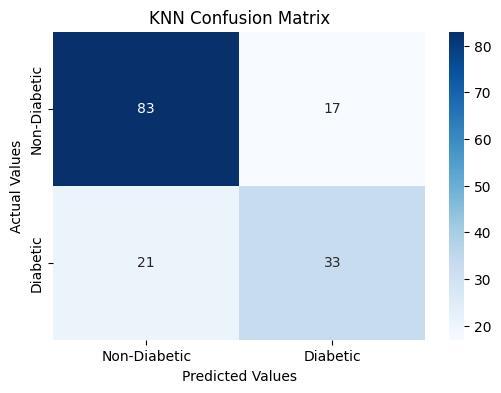

In [10]:
cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:")
print(cm)

# Visualize confusion matrix
plt.figure(figsize=(6, 4))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Non-Diabetic", "Diabetic"],
    yticklabels=["Non-Diabetic", "Diabetic"]
)

plt.title("KNN Confusion Matrix")
plt.xlabel("Predicted Values")
plt.ylabel("Actual Values")

plt.show()

Cell 11 – Calculate accuracy

In [11]:
accuracy = accuracy_score(y_test, y_pred)

print("Accuracy:", accuracy)
print("Accuracy Percentage:", accuracy * 100, "%")

Accuracy: 0.7532467532467533
Accuracy Percentage: 75.32467532467533 %


Cell 12 – Calculate error rate

In [12]:
error_rate = 1 - accuracy

print("Error Rate:", error_rate)
print("Error Rate Percentage:", error_rate * 100, "%")

Error Rate: 0.24675324675324672
Error Rate Percentage: 24.675324675324674 %


Cell 13 – Calculate precision

In [13]:
precision = precision_score(
    y_test,
    y_pred,
    zero_division=0
)

print("Precision:", precision)

Precision: 0.66


Cell 14 – Calculate recall

In [14]:
recall = recall_score(
    y_test,
    y_pred,
    zero_division=0
)

print("Recall:", recall)

Recall: 0.6111111111111112


Cell 15 – Display all evaluation metrics together

In [15]:
print("KNN MODEL PERFORMANCE")

print("-----------------------------")

print("Confusion Matrix:")
print(cm)

print("\nAccuracy:", accuracy)

print("Error Rate:", error_rate)

print("Precision:", precision)

print("Recall:", recall)

KNN MODEL PERFORMANCE
-----------------------------
Confusion Matrix:
[[83 17]
 [21 33]]

Accuracy: 0.7532467532467533
Error Rate: 0.24675324675324672
Precision: 0.66
Recall: 0.6111111111111112
